<a href="https://colab.research.google.com/github/JonathasHFerreira/projetos_jonathas/blob/main/deteccao_fraude.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("ealaxi/paysim1")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'paysim1' dataset.
Path to dataset files: /kaggle/input/paysim1


In [2]:
from mpl_toolkits.mplot3d import Axes3D
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt # plotting
import numpy as np # linear algebra
import os # accessing directory structure
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

In [3]:
print(os.listdir(path))

['PS_20174392719_1491204439457_log.csv']


In [29]:
nRowsRead = 100000

df1 = pd.read_csv(os.path.join(path, 'PS_20174392719_1491204439457_log.csv'), delimiter=',', nrows = nRowsRead)
df1.dataframeName = 'PS_20174392719_1491204439457_log.csv'
nRow, nCol = df1.shape
print(f'There are {nRow} rows and {nCol} columns')

There are 100000 rows and 11 columns


In [30]:
df1.head(10)

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.00,160296.36,M1979787155,0.0,0.00,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.00,19384.72,M2044282225,0.0,0.00,0,0
2,1,TRANSFER,181.00,C1305486145,181.00,0.00,C553264065,0.0,0.00,1,0
3,1,CASH_OUT,181.00,C840083671,181.00,0.00,C38997010,21182.0,0.00,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.00,29885.86,M1230701703,0.0,0.00,0,0
5,1,PAYMENT,7817.71,C90045638,53860.00,46042.29,M573487274,0.0,0.00,0,0
6,1,PAYMENT,7107.77,C154988899,183195.00,176087.23,M408069119,0.0,0.00,0,0
7,1,PAYMENT,7861.64,C1912850431,176087.23,168225.59,M633326333,0.0,0.00,0,0
8,1,PAYMENT,4024.36,C1265012928,2671.00,0.00,M1176932104,0.0,0.00,0,0
9,1,DEBIT,5337.77,C712410124,41720.00,36382.23,C195600860,41898.0,40348.79,0,0


In [31]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 11 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   step            100000 non-null  int64  
 1   type            100000 non-null  object 
 2   amount          100000 non-null  float64
 3   nameOrig        100000 non-null  object 
 4   oldbalanceOrg   100000 non-null  float64
 5   newbalanceOrig  100000 non-null  float64
 6   nameDest        100000 non-null  object 
 7   oldbalanceDest  100000 non-null  float64
 8   newbalanceDest  100000 non-null  float64
 9   isFraud         100000 non-null  int64  
 10  isFlaggedFraud  100000 non-null  int64  
dtypes: float64(5), int64(3), object(3)
memory usage: 8.4+ MB


In [32]:
df1.isnull().sum()

,0
step,0
type,0
amount,0
nameOrig,0
oldbalanceOrg,0
newbalanceOrig,0
nameDest,0
oldbalanceDest,0
newbalanceDest,0
isFraud,0


In [33]:
df1.describe()

,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
count,100000.000000,1.000000e+05,1.000000e+05,1.000000e+05,1.000000e+05,1.000000e+05,100000.000000,100000.0
mean,8.499640,1.736022e+05,8.777575e+05,8.940619e+05,8.805048e+05,1.184041e+06,0.001160,0.0
std,1.825545,3.443003e+05,2.673284e+06,2.711318e+06,2.402267e+06,2.802350e+06,0.034039,0.0
min,1.000000,3.200000e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.0
25%,8.000000,9.963562e+03,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.0
50%,9.000000,5.274552e+04,2.006150e+04,0.000000e+00,2.083943e+04,4.990918e+04,0.000000,0.0
75%,10.000000,2.117631e+05,1.901920e+05,2.148132e+05,5.882724e+05,1.058186e+06,0.000000,0.0
max,10.000000,1.000000e+07,3.379739e+07,3.400874e+07,3.400874e+07,3.894623e+07,1.000000,0.0


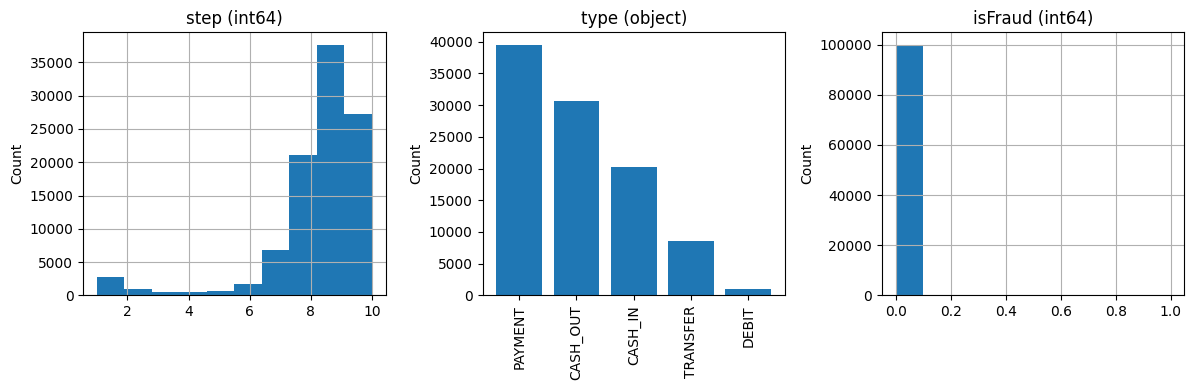

In [34]:
def plotPerColumnDistribution(df, nGraphPerRow, nPerGraph):
    nunique = df.nunique()
    df = df[[col for col in df if nunique[col] > 1 and nunique[col] < 50]].copy() # Reduce to columns with > 1 unique values and < 50 unique values
    nCol = df.shape[1]
    nRow = (nCol + nGraphPerRow - 1) // nGraphPerRow # Calculate number of rows for subplots
    plt.figure(figsize=(nGraphPerRow * 4, nRow * 4)) # Adjust figure size

    for i, col in enumerate(df.columns):
        plt.subplot(nRow, nGraphPerRow, i + 1)
        col_type = df[col].dtype
        if col_type == 'object' or col_type.name == 'category': # Categorical
            if nunique[col] > nPerGraph:
                # Plot top nPerGraph values
                temp_counts = df[col].value_counts().nlargest(nPerGraph)
                plt.bar(temp_counts.index, temp_counts.values)
                plt.xticks(rotation=90)
            else:
                # Plot all values
                temp_counts = df[col].value_counts()
                plt.bar(temp_counts.index, temp_counts.values)
                plt.xticks(rotation=90)
        else: # Numerical
            df[col].hist()
        plt.title(f'{col} ({col_type})')
        plt.ylabel('Count')
    plt.tight_layout()
    plt.show()

plotPerColumnDistribution(df1, 10, 5)

### Instalando e importando as bibliotecas necessárias para o SMOTE

In [10]:
!pip install -q imbalanced-learn

import pandas as pd
from imblearn.over_sampling import SMOTE
from collections import Counter

### Preparando os dados e aplicando o SMOTE
Como o SMOTE trabalha apenas com dados numéricos e não aceita colunas de texto sem codificação, vamos selecionar apenas as colunas numéricas para esta demonstração.

In [35]:
# 1. Selecionando colunas numéricas úteis e removendo IDs/textos
colunas_numericas = ['step', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest']

X = df1[colunas_numericas]
y = df1['isFraud']

print("Distribuição das classes antes do SMOTE:", Counter(y))

# 2. Inicializando e aplicando o SMOTE
smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X, y)

print("Distribuição das classes após o SMOTE:", Counter(y_resampled))

Distribuição das classes antes do SMOTE: Counter({0: 99884, 1: 116})
Distribuição das classes após o SMOTE: Counter({0: 99884, 1: 99884})


### Divisão dos dados balanceados e Treinamento do Random Forest

In [45]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Divisão em Treino e Teste
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

print(f"Tamanho do treino: {X_train.shape[0]} amostras")
print(f"Tamanho do teste: {X_test.shape[0]} amostras")

Tamanho do treino: 70000 amostras
Tamanho do teste: 30000 amostras


In [46]:
# 2. Treinamento do Modelo (usando n_estimators reduzido e n_jobs=-1 para otimizar o tempo de execução)
rf_model = RandomForestClassifier(n_estimators=50, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

RandomForestClassifier(n_estimators=50, n_jobs=-1, random_state=42)

Acurácia: 0.9991

Relatório de Classificação:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     29965
           1       0.79      0.31      0.45        35

    accuracy                           1.00     30000
   macro avg       0.89      0.66      0.72     30000
weighted avg       1.00      1.00      1.00     30000



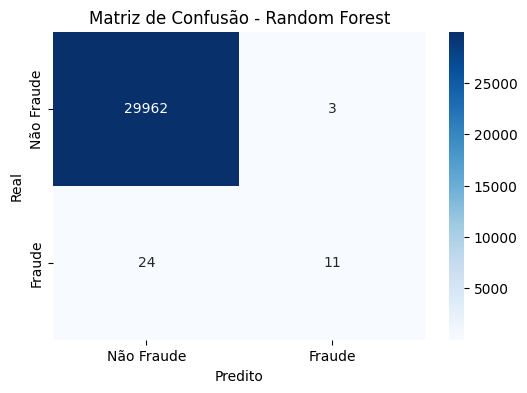

In [47]:
# 3. Avaliação do Modelo
y_pred = rf_model.predict(X_test)

print("Acurácia:", accuracy_score(y_test, y_pred))
print("\nRelatório de Classificação:")
print(classification_report(y_test, y_pred))

# Matriz de Confusão
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Não Fraude', 'Fraude'], yticklabels=['Não Fraude', 'Fraude'])
plt.xlabel('Predito')
plt.ylabel('Real')
plt.title('Matriz de Confusão - Random Forest')
plt.show()

### Curva ROC e AUC para o Modelo Random Forest

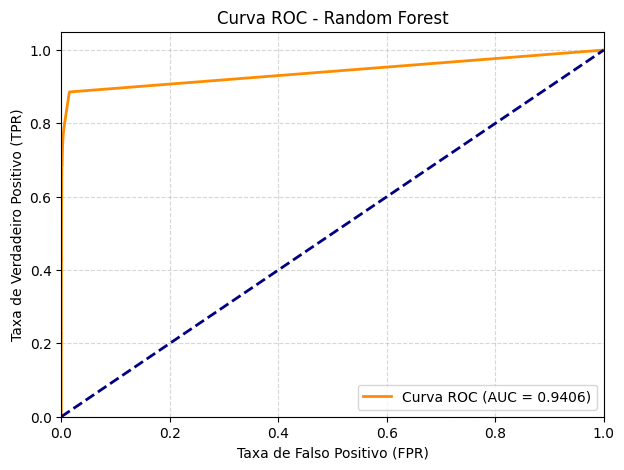

In [48]:
from sklearn.metrics import roc_curve, auc

# 1. Obter as probabilidades para a classe positiva (Fraude)
y_probs = rf_model.predict_proba(X_test)[:, 1]

# 2. Calcular a taxa de verdadeiros positivos (TPR) e falsos positivos (FPR)
fpr, tpr, thresholds = roc_curve(y_test, y_probs)
roc_auc = auc(fpr, tpr)

# 3. Plotar a Curva ROC
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'Curva ROC (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taxa de Falso Positivo (FPR)')
plt.ylabel('Taxa de Verdadeiro Positivo (TPR)')
plt.title('Curva ROC - Random Forest')
plt.legend(loc="lower right")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Comparação com o XGBoost Classifier

In [49]:
!pip install -q xgboost

import xgboost as xgb
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_curve, auc

In [50]:
# 1. Inicializar e Treinar o modelo XGBoost
xgb_model = xgb.XGBClassifier(n_estimators=50, random_state=42, n_jobs=-1, eval_metric='logloss')
xgb_model.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=50, n_jobs=-1,
              num_parallel_tree=None, ...)

In [51]:
# 2. Avaliação do XGBoost
y_pred_xgb = xgb_model.predict(X_test)
y_probs_xgb = xgb_model.predict_proba(X_test)[:, 1]

print("Acurácia XGBoost:", accuracy_score(y_test, y_pred_xgb))
print("\nRelatório de Classificação XGBoost:")
print(classification_report(y_test, y_pred_xgb))

Acurácia XGBoost: 0.9991

Relatório de Classificação XGBoost:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     29965
           1       0.75      0.34      0.47        35

    accuracy                           1.00     30000
   macro avg       0.87      0.67      0.74     30000
weighted avg       1.00      1.00      1.00     30000



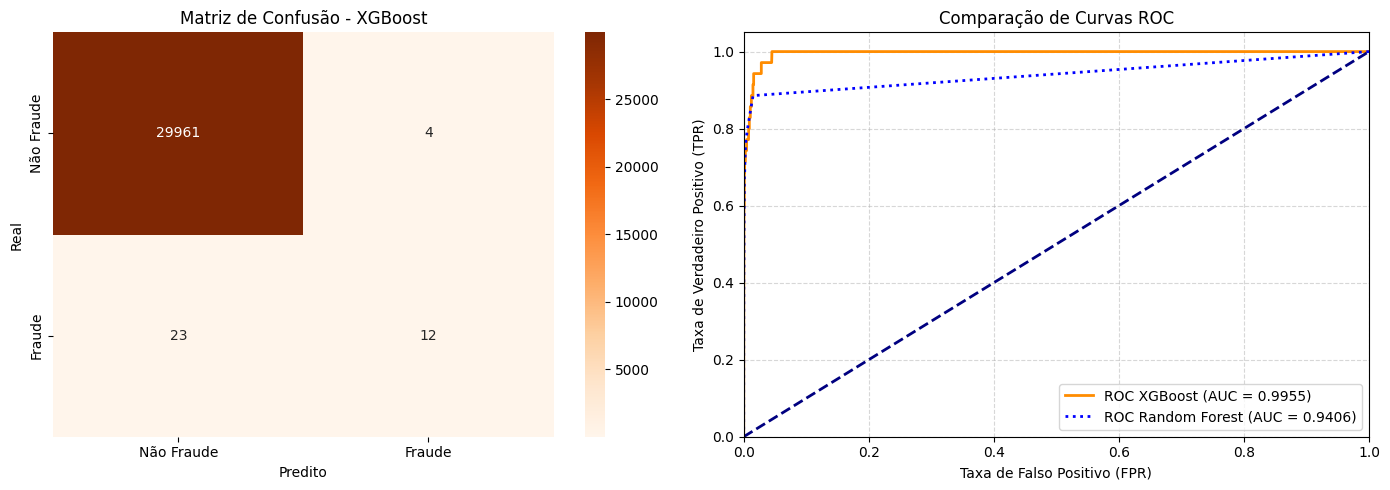

In [52]:
# 3. Matriz de Confusão e Curva ROC para o XGBoost
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Matriz de Confusão
cm_xgb = confusion_matrix(y_test, y_pred_xgb)
sns.heatmap(cm_xgb, annot=True, fmt='d', cmap='Oranges',
            xticklabels=['Não Fraude', 'Fraude'], yticklabels=['Não Fraude', 'Fraude'], ax=ax[0])
ax[0].set_xlabel('Predito')
ax[0].set_ylabel('Real')
ax[0].set_title('Matriz de Confusão - XGBoost')

# Curva ROC
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_probs_xgb)
roc_auc_xgb = auc(fpr_xgb, tpr_xgb)

ax[1].plot(fpr_xgb, tpr_xgb, color='darkorange', lw=2, label=f'ROC XGBoost (AUC = {roc_auc_xgb:.4f})')
ax[1].plot(fpr, tpr, color='blue', lw=2, linestyle=':', label=f'ROC Random Forest (AUC = {roc_auc:.4f})')
ax[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
ax[1].set_xlim([0.0, 1.0])
ax[1].set_ylim([0.0, 1.05])
ax[1].set_xlabel('Taxa de Falso Positivo (FPR)')
ax[1].set_ylabel('Taxa de Verdadeiro Positivo (TPR)')
ax[1].set_title('Comparação de Curvas ROC')
ax[1].legend(loc="lower right")
ax[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### Visualização da Importância das Features com o XGBoost

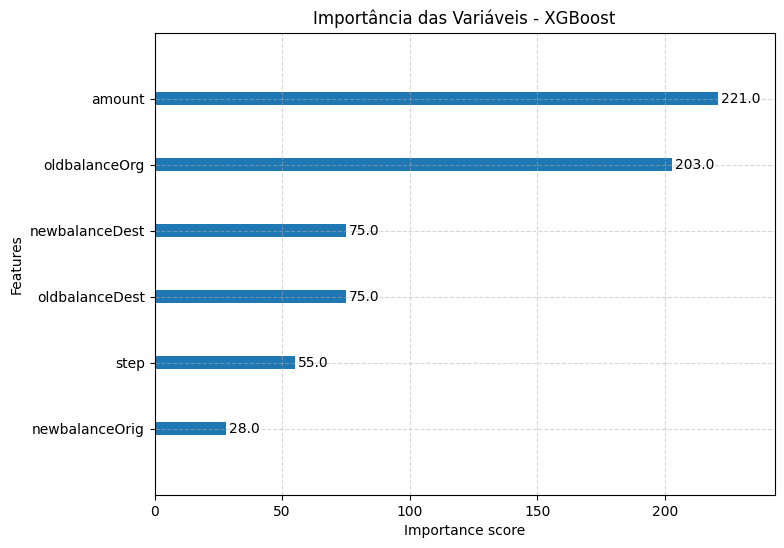

In [53]:
import matplotlib.pyplot as plt

# Plotando a importância das variáveis
plt.figure(figsize=(8, 6))
xgb.plot_importance(xgb_model, importance_type='weight', max_num_features=10, ax=plt.gca())
plt.title('Importância das Variáveis - XGBoost')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Gráfico de Correlação das Variáveis Mais Importantes

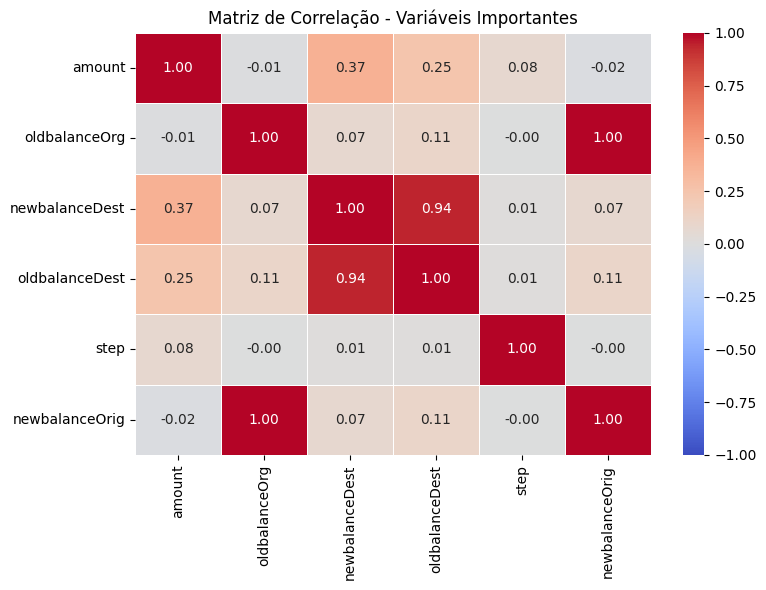

In [54]:
import seaborn as sns
import matplotlib.pyplot as plt

# Selecionando as variáveis de maior importância identificadas pelo modelo
variaveis_importantes = ['amount', 'oldbalanceOrg', 'newbalanceDest', 'oldbalanceDest', 'step', 'newbalanceOrig']
corr_matrix = df1[variaveis_importantes].corr()

# Gerando o gráfico de correlação
plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    vmin=-1,
    vmax=1
)
plt.title('Matriz de Correlação - Variáveis Importantes')
plt.tight_layout()
plt.show()